In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV, RandomizedSearchCV
from sklearn.metrics import classification_report, confusion_matrix
import time


In [2]:
data = pd.read_csv("diabetes.csv")
data.shape

(768, 9)

In [3]:

X = data.iloc[:, :-1].values

y = data.iloc[:, -1].values


In [4]:
X

array([[  6.   , 148.   ,  72.   , ...,  33.6  ,   0.627,  50.   ],
       [  1.   ,  85.   ,  66.   , ...,  26.6  ,   0.351,  31.   ],
       [  8.   , 183.   ,  64.   , ...,  23.3  ,   0.672,  32.   ],
       ...,
       [  5.   , 121.   ,  72.   , ...,  26.2  ,   0.245,  30.   ],
       [  1.   , 126.   ,  60.   , ...,  30.1  ,   0.349,  47.   ],
       [  1.   ,  93.   ,  70.   , ...,  30.4  ,   0.315,  23.   ]],
      shape=(768, 8))

In [5]:
y

array([1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0,
       1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1,
       0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0,
       1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1,
       1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1,
       0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1,
       1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1,
       1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0,
       1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0,
       1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0,
       0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 1,

In [6]:

model = DecisionTreeClassifier(random_state=42)


In [7]:

kfold = KFold(n_splits=5)

cv_result = cross_val_score(model, X, y, cv=kfold, scoring='accuracy')

cv_result

array([0.71428571, 0.61688312, 0.73376623, 0.80392157, 0.71895425])

In [8]:
print("Mean CV Accuracy:", cv_result.mean()*100)

Mean CV Accuracy: 71.75621763857059


In [9]:

param_grid = {
    'max_depth': [3, 4, 5, 6, 7, 8, None],
    'min_samples_split': [ 2, 5, 10],
    'criterion': ['gini', 'entropy']
}

grid = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid, cv=3, scoring='accuracy', n_jobs=-1)

start_time = time.time()
grid_result = grid.fit(X, y)
grid_time = time.time() - start_time

print("GridSearchCV Best Accuracy: %.4f using %s" % (grid_result.best_score_, grid_result.best_params_))
print("Execution Time: %.2f seconds" % grid_time)


GridSearchCV Best Accuracy: 0.7487 using {'criterion': 'entropy', 'max_depth': 4, 'min_samples_split': 5}
Execution Time: 12.84 seconds


In [10]:

random = RandomizedSearchCV(DecisionTreeClassifier(random_state=42),
                            param_distributions=param_grid,
                            #n_iter=10,
                            cv=3,
                            scoring='accuracy',
                            n_jobs=-1,
                            random_state=42)

start_time = time.time()
random_result = random.fit(X, y)
random_time = time.time() - start_time

print("RandomizedSearchCV Best Accuracy: %.4f using %s" % (random_result.best_score_, random_result.best_params_))
print("Execution Time: %.2f seconds" % random_time)


RandomizedSearchCV Best Accuracy: 0.7487 using {'min_samples_split': 5, 'max_depth': 4, 'criterion': 'entropy'}
Execution Time: 0.11 seconds


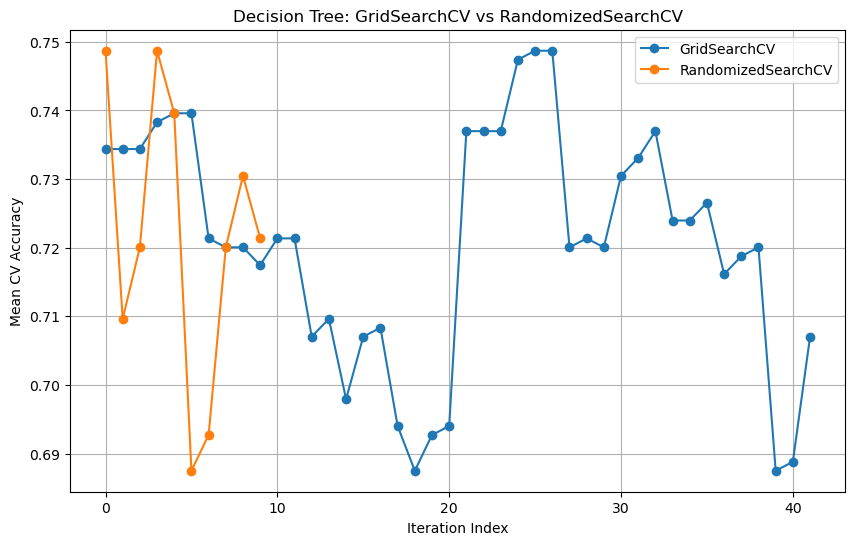

In [11]:

grid_df = pd.DataFrame(grid_result.cv_results_)
grid_df['search'] = 'GridSearchCV'

random_df = pd.DataFrame(random_result.cv_results_)
random_df['search'] = 'RandomizedSearchCV'

combined_df = pd.concat([grid_df, random_df])

plt.figure(figsize=(10, 6))
for label, df in combined_df.groupby('search'):
    plt.plot(df['mean_test_score'].values, marker='o', label=label)

plt.xlabel("Iteration Index")
plt.ylabel("Mean CV Accuracy")
plt.title("Decision Tree: GridSearchCV vs RandomizedSearchCV")
plt.legend()
plt.grid(True)
plt.show()


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import time

In [13]:
data = pd.read_csv("diabetes.csv")

X = data.iloc[:, :-1].values
y = data.iloc[:, -1].values

In [14]:
# Stratified Train / Val / Test Split

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=0.25,     # 0.25 of 0.8 = 0.20
    random_state=42,
    stratify=y_train_full
)

print("Dataset Split Sizes")
print(f"Train: {X_train.shape[0]}")
print(f"Validation: {X_val.shape[0]}")
print(f"Test: {X_test.shape[0]}")


Dataset Split Sizes
Train: 460
Validation: 154
Test: 154


In [15]:
# Model

dt = DecisionTreeClassifier(random_state=42)


In [16]:
# Hyperparameter Grid

param_grid = {
    'max_depth': [3, 4, 5, 6, 7, 8, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'criterion': ['gini', 'entropy'],
    'max_features': [None, 'sqrt', 'log2']
}


In [17]:
# GridSearchCV

grid = GridSearchCV(
    dt,
    param_grid,
    cv=3,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

start_time = time.time()
grid_result = grid.fit(X_train, y_train)
grid_time = time.time() - start_time

print("\nGridSearchCV Best Accuracy: %.4f" % grid_result.best_score_)
print("Best Params:", grid_result.best_params_)
print("Execution Time: %.2f seconds" % grid_time)


Fitting 3 folds for each of 378 candidates, totalling 1134 fits

GridSearchCV Best Accuracy: 0.7521
Best Params: {'criterion': 'entropy', 'max_depth': 7, 'max_features': 'sqrt', 'min_samples_leaf': 4, 'min_samples_split': 10}
Execution Time: 1.47 seconds


In [18]:

# RandomizedSearchCV

random = RandomizedSearchCV(
    dt,
    param_distributions=param_grid,
    n_iter=10,
    cv=3,
    scoring='accuracy',
    n_jobs=-1,
    random_state=42,
    verbose=1
)

start_time = time.time()
random_result = random.fit(X_train, y_train)
random_time = time.time() - start_time

print("\nRandomizedSearchCV Best Accuracy: %.4f" % random_result.best_score_)
print("Best Params:", random_result.best_params_)
print("Execution Time: %.2f seconds" % random_time)


Fitting 3 folds for each of 10 candidates, totalling 30 fits

RandomizedSearchCV Best Accuracy: 0.7348
Best Params: {'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': None, 'max_depth': 5, 'criterion': 'gini'}
Execution Time: 0.10 seconds


In [19]:

# Best Model from Grid Search

best_model = grid_result.best_estimator_
best_model

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",7
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",4
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",'sqrt'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the curr

In [20]:

# Validation Evaluation

y_val_pred = best_model.predict(X_val)

print("\n===== VALIDATION RESULTS =====")
print("Validation Accuracy:", accuracy_score(y_val, y_val_pred))
print("Confusion Matrix:\n", confusion_matrix(y_val, y_val_pred))
print("Classification Report:\n", classification_report(y_val, y_val_pred))



===== VALIDATION RESULTS =====
Validation Accuracy: 0.7337662337662337
Confusion Matrix:
 [[85 15]
 [26 28]]
Classification Report:
               precision    recall  f1-score   support

           0       0.77      0.85      0.81       100
           1       0.65      0.52      0.58        54

    accuracy                           0.73       154
   macro avg       0.71      0.68      0.69       154
weighted avg       0.73      0.73      0.73       154



In [21]:

# Final Test Evaluation

y_test_pred = best_model.predict(X_test)

print("Test Accuracy:", accuracy_score(y_test, y_test_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_test_pred))
print("Classification Report:\n", classification_report(y_test, y_test_pred))


Test Accuracy: 0.6753246753246753
Confusion Matrix:
 [[79 21]
 [29 25]]
Classification Report:
               precision    recall  f1-score   support

           0       0.73      0.79      0.76       100
           1       0.54      0.46      0.50        54

    accuracy                           0.68       154
   macro avg       0.64      0.63      0.63       154
weighted avg       0.67      0.68      0.67       154



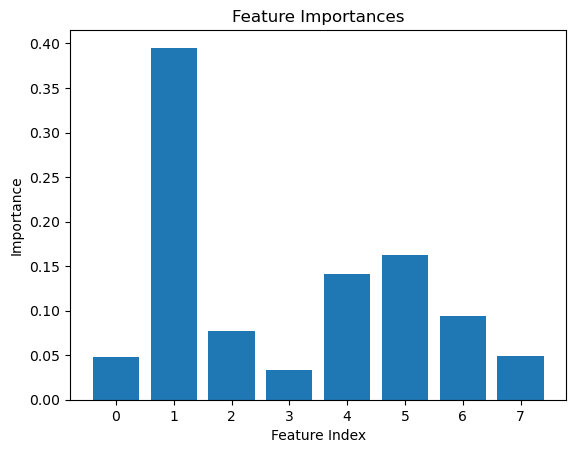

In [22]:

# Optional: Feature Importance Plot

importances = best_model.feature_importances_

plt.figure()
plt.bar(range(len(importances)), importances)
plt.title("Feature Importances")
plt.xlabel("Feature Index")
plt.ylabel("Importance")
plt.show()
